In [29]:
import random
import time
# %pip install "gymnasium[classic-control]"
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as opt

In [37]:
# %%
# settings
env_id = "CartPole-v1"

# number of environments to run in parallel
num_envs = 1

# total number of timesteps for training over multiple episodes
total_timesteps = 100_000

# adam learning rate
learning_rate = 2e-3

# discount factor
gamma = 0.99

# epsilon value for epsilon-greedy
eps = 0.1

# seed for reproducibility
seed = None

# number of transitions to store in replay buffer
buffer_size = 10_000

# target network update constant - Polyak Averaging
# θ_target = τ * θ_online + (1 - τ) * θ_target
tau = 1.0

# number of timesteps between target network updates
target_network_frequency = 50

# size of sample from teplay buffer
batch_size = 32

# initial value of epsilon (%100 exploration)
start_eps = 1

# final value of epsilon (%1 exploration)
end_eps = 0.01

# number of steps to decrease from start_eps to end_eps
# currently %10 of the total (also equals to buffer_size, by coincedence)
exploration_duration = int(0.1 * total_timesteps)

# number of steps before beginning training
# we are not even going to wait to be full (5000 < buffer_size)
num_steps_before_training = 5_000

# number of steps between each gradient descent step
# sample a batch from the replay buffer and then train on that
train_frequency = 4 # times interactions with the environment

video_path = "qlearning_cartpole_videos"

device = torch.device(
    "cuda" if torch.cuda.is_available() else
    "cpu"
)

In [38]:
def make_env(env_id, capture_video, seed=None):
    if capture_video:
        env = gym.make(env_id, render_mode="rgb_array")
        env = gym.wrappers.RecordVideo(env, video_path, episode_trigger=lambda episode: True)
    else:
        env = gym.make(env_id)

    env = gym.wrappers.RecordEpisodeStatistics(env)

    if seed is not None:
        env.action_space.seed(seed)

    return env

In [39]:
# NN
class QNetwork(nn.Module):

    def __init__(self, envs, n_hidden=128):
        super().__init__()

        self.network = nn.Sequential(
                        nn.Linear(np.array(envs.single_observation_space.shape).prod(), n_hidden),
                        nn.ReLU(),
                        nn.Linear(n_hidden, envs.single_action_space.n)
        )

    def forward(self, state_x):
        return self.network(state_x)

def np2torch(a, to_float=True):
    if to_float:
        dtype = torch.float32
    else:
        dtype = torch.int64

    return torch.as_tensor(a, dtype=dtype, device=device)

In [33]:
def linear_schedule(start_eps, end_eps, duration, t):
    slope = (end_eps - start_eps) / duration
    return max(slope*t + start_eps, end_eps)

In [34]:
# make environaments
envs = gym.vector.SyncVectorEnv(
    [
        lambda i=i: make_env(
            env_id,
            False,
            seed=None if seed is None else seed + i*10,
        )
        for i in range(num_envs)
    ]
)

In [35]:

class ReplayBuffer:
    def __init__(self, obs_dim, size):
        if obs_dim is None:
            obs_dim = 1
            
        self.obs1_buf = np.zeros([size, obs_dim], dtype=np.float32)
        self.obs2_buf = np.zeros([size, obs_dim], dtype=np.float32)
        self.acts_buf = np.zeros(size, dtype=np.uint8)
        self.rews_buf = np.zeros(size, dtype=np.float32)
        self.done_buf = np.zeros(size, dtype=np.uint8)
        self.ptr, self.size, self.max_size = 0, 0, size

    def store(self, obs, act, rew, next_obs, done):
        self.obs1_buf[self.ptr] = obs
        self.obs2_buf[self.ptr] = next_obs
        self.acts_buf[self.ptr] = act
        self.rews_buf[self.ptr] = rew
        self.done_buf[self.ptr] = done

        self.ptr = (self.ptr + 1) % self.max_size
        self.size = min(self.size + 1, self.max_size)

    def sample_batch(self, batch_size=32):
        idxs = np.random.randint(0, self.size, size=batch_size)

        return dict(
            s=self.obs1_buf[idxs],
            s2=self.obs2_buf[idxs],
            a=self.acts_buf[idxs],
            r=self.rews_buf[idxs],
            d=self.done_buf[idxs]
        )


In [40]:
episode_returns = []
losses = []
current_state_obs, _ = envs.reset(seed=seed) # States [B, 4] [B=1, [Cart position, Cart velocity, Pole angle, Pole angular velocity]]
auto_reset = np.zeros(num_envs, dtype = bool)

# Online Q-Network
q_network = QNetwork(envs).to(device) # state --> NN --> Q(s,a), where predicted_value = Q(s,a).max() and predicted_action = arg_max(Q(s,a))

# Target Q-Network
target_network = QNetwork(envs).to(device)
target_network.load_state_dict(q_network.state_dict()) # copy main to target

optimizer = opt.Adam(q_network.parameters(), lr=learning_rate)

rb = ReplayBuffer(envs.single_observation_space.shape[0], buffer_size)

start_time = time.time()
for global_step in range(total_timesteps):
    
    #select action(s) by epsilon-greedy method
    # decrease epsilon over time to explore less exploit more
    epsilon = linear_schedule(start_eps, end_eps, exploration_duration, global_step)

    if random.random() < epsilon:
        actions = np.array([envs.single_action_space.sample() for _ in range(num_envs)])
    else:
        # select best actions by arg_max from NN (Q(s,a))
        q_values = q_network(np2torch(current_state_obs))
        actions = torch.argmax(q_values, dim=1).cpu().numpy() # predicted_actions = arg_max(Q(s,a))

    # get s', R, done - take a step in the environment
    next_state_obs, rewards, terminateds, truncateds, infos = envs.step(actions)

    # record returns for plotting and update episode_returns
    for i, (terminated, truncated) in enumerate(zip(terminateds, truncateds)):
        if terminated or truncated:
            ret = infos['episode']['r'][i] # accumulated rewards
            episode_returns.append(ret)
            print(f"global_step = {global_step}, episode = {len(episode_returns)}, episode_return = {ret}")

    # update replay buffer
    # every episode that hasn't ended essentially we should add this transition to the replay buffer.
    for i in range(num_envs):
        if not auto_reset[i]:
            rb.store(current_state_obs[i], actions[i], rewards[i], next_state_obs[i], terminateds[i])

    # go to the next state
    current_state_obs = next_state_obs

    # update auto reset
    auto_reset = np.logical_or(terminateds, truncateds)

    # training
    #   We're not training on every step.
    #   We're taking the first few steps to add samples to the replay buffer and just perform random actions

    if global_step > num_steps_before_training:
        if global_step % train_frequency == 0:

            # get sample batch from the replay buffer
            batch = rb.sample_batch(batch_size)

            with torch.no_grad():
                replay_next_state_obs = np2torch(batch["s2"])
                replay_rewards = np2torch(batch["r"].flatten())
                # get the next max(Q(s', a'))
                replay_next_max_q_values = target_network(replay_next_state_obs).max(dim=1).values
                # Bellman: Q(s,a) = Q(s,a) + α * (R + γ * (max(Q(s', a'))) - Q(s,a))  --> ( Q(s,a) = Q(s,a) + α * (target - Q(s,a)))
                replay_target = replay_rewards + gamma * (1 - np2torch(batch["d"].flatten())) * replay_next_max_q_values

            replay_actions = np2torch(batch["a"], to_float=False)
            replay_current_state_obs = np2torch(batch["s"])

            # prediction: forward by masked Q(s) and get the values Q(s,a) for the actions performed (gather)
            current_replay_q_values = q_network(np2torch(replay_current_state_obs)) # [B, 2 (left, right)]

            # gather() selects the Q-value of the action actually performed, not the action with the maximum Q-value. 
            # This is exactly what we want when computing the prediction term (Q(s,a) in the loss function
            replay_q_values_performed = torch.gather(
                                        input=current_replay_q_values, 
                                        dim=1, 
                                        index = replay_actions.reshape(-1,1)
                                        ) # [B, 1]            

            #prepare the dimensions for the loss function
            replay_q_values_predictions = replay_q_values_performed.squeeze(1)  # [B]

            loss = F.mse_loss(replay_q_values_predictions, replay_target)
            losses.append(loss.detach().cpu().numpy())

            # optimize
            optimizer.zero_grad()
            loss.backward()
            # update
            optimizer.step()            

        if global_step % 1000 == 0:
            print("steps per second:", int(global_step / (time.time() - start_time)))

        # update the target network
        if global_step % target_network_frequency == 0:
            for target_network_param, q_network_param in zip(target_network.parameters(), q_network.parameters()):
                target_network_param.data.copy_(tau * q_network_param.data + (1.0 - tau) * target_network_param.data)

        # let's brek if the last 10 episodes had max reward
        if(len(episode_returns)) > 10 and np.all(np.equal(episode_returns[-10:], 500)):
            print("max reward achieved")
            break

envs.close() 


global_step = 10, episode = 1, episode_return = 11.0
global_step = 44, episode = 2, episode_return = 33.0
global_step = 72, episode = 3, episode_return = 27.0
global_step = 102, episode = 4, episode_return = 29.0
global_step = 124, episode = 5, episode_return = 21.0
global_step = 167, episode = 6, episode_return = 42.0
global_step = 194, episode = 7, episode_return = 26.0
global_step = 220, episode = 8, episode_return = 25.0
global_step = 241, episode = 9, episode_return = 20.0
global_step = 270, episode = 10, episode_return = 28.0
global_step = 290, episode = 11, episode_return = 19.0
global_step = 311, episode = 12, episode_return = 20.0
global_step = 328, episode = 13, episode_return = 16.0
global_step = 344, episode = 14, episode_return = 15.0
global_step = 364, episode = 15, episode_return = 19.0
global_step = 374, episode = 16, episode_return = 9.0
global_step = 409, episode = 17, episode_return = 34.0
global_step = 432, episode = 18, episode_return = 22.0
global_step = 455, epis

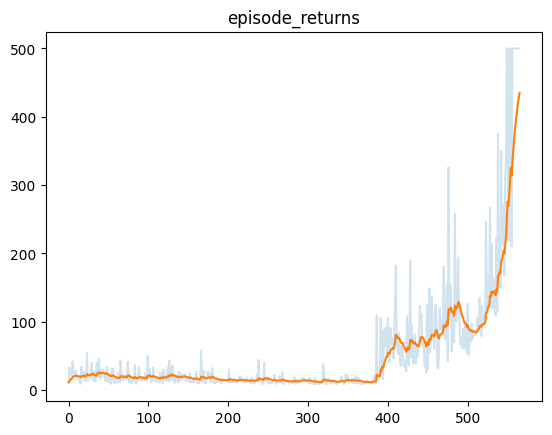

In [41]:
def smooth(x, a=0.1):
    y = [x[0]]
    for xi in x[1:]:
        yi = a * xi + (1-a) * y[-1]
        y.append(yi)
    return y

plt.plot(episode_returns, alpha=0.2)
plt.plot(smooth(episode_returns))
plt.title("episode_returns")
plt.show()

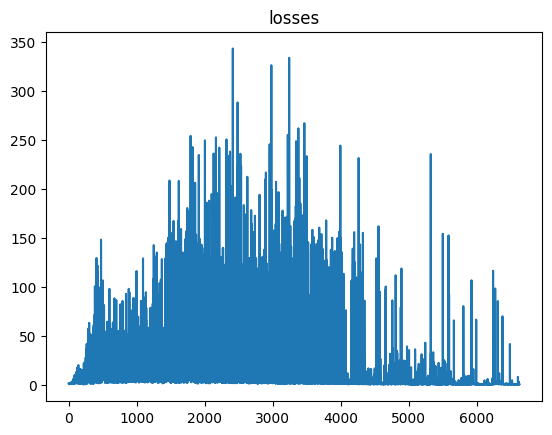

In [42]:
plt.plot(losses)
plt.title("losses")
plt.show()

In [43]:
# save model
model_path = "/workspace/repos/jupyter_notebooks/Reinforcement_Learning/DQN_1.pth"
torch.save(q_network.state_dict(), model_path)

In [44]:
# load the model for eval
# %pip install "gymnasium[other]"
envs_eval = gym.vector.SyncVectorEnv([lambda: make_env(env_id, True)]) # open with recording
model = QNetwork(envs_eval).to(device)
model.load_state_dict(torch.load(model_path, map_location=device))
model.eval()


/usr/local/lib/python3.12/dist-packages/gymnasium/wrappers/rendering.py:298: UserWarning: WARN: Overwriting existing videos at /workspace/repos/jupyter_notebooks/Reinforcement_Learning/qlearning_cartpole_videos folder (try specifying a different `video_folder` for the `RecordVideo` wrapper if this is not desired)
  logger.warn(
/usr/local/lib/python3.12/dist-packages/gymnasium/wrappers/rendering.py:443: UserWarning: WARN: Unable to save last video! Did you call close()?
  logger.warn("Unable to save last video! Did you call close()?")


QNetwork(
  (network): Sequential(
    (0): Linear(in_features=4, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=2, bias=True)
  )
)

In [45]:
# evaluate the model
n_episodes_eval = 3
eval_returns = np.zeros(n_episodes_eval)
state_obs, _ = envs_eval.reset(seed=500)

for i in range(n_episodes_eval):
    episode_done = False

    while not episode_done:
        q_values = model(np2torch(state_obs))
        actions = torch.argmax(q_values, dim=1).cpu().numpy()
        state_obs, rewards, terminateds, truncateds, infos = envs_eval.step(actions)

        if terminateds[0] or truncateds[0]:
            G = infos['episode']['r'][0]
            print(f"episode: {i}, return= {G}")
            eval_returns[i] = G
            episode_done = True

envs_eval.close() 

episode: 0, return= 500.0
episode: 1, return= 500.0
episode: 2, return= 500.0


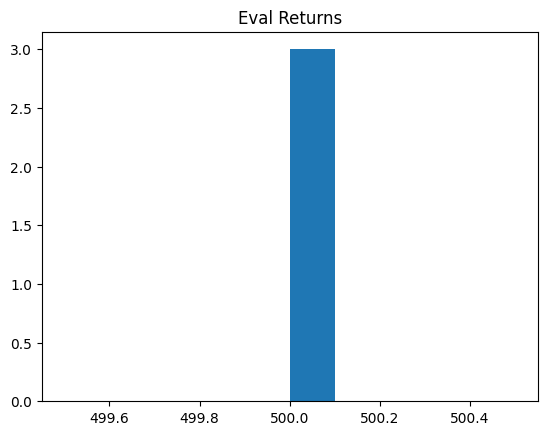

In [46]:
plt.hist(eval_returns)
plt.title("Eval Returns")
plt.show();

In [47]:
# prompt display video in notebook
from IPython.display import HTML
from base64 import b64encode

mp4 = open(f'{video_path}/rl-video-episode-2.mp4', 'rb').read()
data_url = "data:video/mp4;base64," + b64encode(mp4).decode()

HTML("""
<video width=400 controls>
    <source src="%s" type="video/mp4">
</video>
""" % data_url)